# Beta-convergência condicional entre os estados brasileiros, 2002–2023

Estima a beta-convergência condicional na especificação de Solow, com a taxa de investimento e o crescimento populacional como controles, e apresenta a relação entre escolaridade e renda inicial (seção 4.2.2 do TCC).

Os dados vêm do Ipeadata e devem estar na pasta `../dados_usados` (ver o README do repositório).

In [1]:
# ----------------------------------------------------------------------------
# 1. BIBLIOTECAS E PARÂMETROS
# ----------------------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
import matplotlib.pyplot as plt

# O notebook fica na pasta BETACONVERGENCIA; os dados, em TCC\dados_usados
PASTA_DADOS = os.path.join("..", "dados_usados")
ARQ = {
    "pibpc":  "PIBPCE_pib_estadual_per_capita_precos_2010_[17-08-2026].csv",
    "pop":    "POP_PROJE_populacao_residente_projecao_IBGE_[10-11-2026].csv",
    "invest": "DINVESTE_despesa_capital_investimento_estadual_[10-11-2026].csv",
    "pib":    "PIBPMCE_pib_estadual_precos_correntes_[10-11-2026].csv",
    "educ":   "MEDUCA_anos_medios_estudo_25_anos_ou_mais_censo_[10-11-2026].csv",
}

ANO_INICIAL  = 2002
ANO_FINAL    = 2023
TAU          = ANO_FINAL - ANO_INICIAL     # 21 anos, como na absoluta
ANOS_R1      = [2000, 2001, 2002]          # valores iniciais (robustez R1)
ANO_EDUC     = 2000                        # Censo usado na parte descritiva
G_MAIS_DELTA = 0.05                        # Mankiw, Romer e Weil (1992, p. 413)
GMD_SENS     = [0.04, 0.05, 0.06]          # sensibilidade
TIPO_EP      = "HC3"
NIVEIS       = [0.05, 0.01]
PREFIXO      = "condicional_solow_"

PASTA_TAB = os.path.join("resultados", "tabelas")
PASTA_FIG = os.path.join("resultados", "figuras")
for pasta in [PASTA_TAB, PASTA_FIG]:
    os.makedirs(pasta, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
# ----------------------------------------------------------------------------
# 2. LEITURA E VALIDAÇÃO
# ----------------------------------------------------------------------------
def ler_csv_ipeadata(nome):
    """Lê um CSV do Ipeadata (1ª linha = título; 2ª = Sigla, Código, Estado, anos).
    Devolve uma tabela com uma linha por estado (índice = sigla) e uma coluna por ano."""
    d = pd.read_csv(os.path.join(PASTA_DADOS, nome), skiprows=1, encoding="utf-8-sig")
    d = d.loc[:, ~d.columns.str.startswith("Unnamed")]
    anos = [c for c in d.columns if c.isdigit()]
    t = d.set_index("Sigla")[anos].astype(float)
    t.columns = t.columns.astype(int)
    assert t.shape[0] == 27 and t.index.nunique() == 27, f"{nome}: não há 27 UF"
    return t, d.set_index("Sigla")["Estado"]

pibpc,  nomes = ler_csv_ipeadata(ARQ["pibpc"])
pop,    _     = ler_csv_ipeadata(ARQ["pop"])
invest, _     = ler_csv_ipeadata(ARQ["invest"])
pib,    _     = ler_csv_ipeadata(ARQ["pib"])
educ,   _     = ler_csv_ipeadata(ARQ["educ"])

anos_principal = list(range(ANO_INICIAL, ANO_FINAL + 1))
for nome, t, anos in [("PIBPCE", pibpc, anos_principal),
                      ("POP_PROJE", pop, ANOS_R1 + anos_principal),
                      ("DINVESTE", invest, ANOS_R1 + anos_principal),
                      ("PIBPMCE", pib, ANOS_R1 + anos_principal),
                      ("MEDUCA", educ, [ANO_EDUC])]:
    faltam = sorted(set(anos) - set(t.columns))
    assert not faltam, f"{nome}: faltam os anos {faltam}"
    assert t[sorted(set(anos))].isna().sum().sum() == 0, f"{nome}: há valores ausentes"

zeros = [(uf, ano) for uf in invest.index for ano in invest.columns if invest.loc[uf, ano] == 0]
print("Investimento estadual igual a zero (tratado como ausente):", zeros)
invest = invest.replace(0, np.nan)
print("Leitura validada: 27 UF em todas as séries; anos necessários presentes.")

Investimento estadual igual a zero (tratado como ausente): [('RR', 2010), ('RR', 2011)]
Leitura validada: 27 UF em todas as séries; anos necessários presentes.


In [3]:
# ----------------------------------------------------------------------------
# 3. CONSTRUÇÃO DAS VARIÁVEIS (corte transversal: uma linha por estado)
# ----------------------------------------------------------------------------
taxa_inv = invest / (pib * 1000)          # DINVESTE em R$; PIBPMCE em R$ mil

base = pd.DataFrame(index=pibpc.index)
base["Estado"] = nomes
base["ln_y0"] = np.log(pibpc[ANO_INICIAL])
base["cresc_medio"] = (np.log(pibpc[ANO_FINAL]) - np.log(pibpc[ANO_INICIAL])) / TAU

base["sk"]     = taxa_inv[anos_principal].mean(axis=1, skipna=True)
base["n"]      = np.log(pop[ANO_FINAL] / pop[ANO_INICIAL]) / TAU
base["sk_ini"] = taxa_inv[ANOS_R1].mean(axis=1)
base["n_ini"]  = np.log(pop[ANOS_R1[-1]] / pop[ANOS_R1[0]]) / (ANOS_R1[-1] - ANOS_R1[0])
base["sh"]     = educ[ANO_EDUC]           # só para a parte descritiva (seção 10)

def montar_logs(b, gmd=G_MAIS_DELTA):
    b = b.copy()
    b["ln_sk"]      = np.log(b["sk"])
    b["ln_ngd"]     = np.log(b["n"] + gmd)
    b["ln_sk_ini"]  = np.log(b["sk_ini"])
    b["ln_ngd_ini"] = np.log(b["n_ini"] + gmd)
    b["ln_sh"]      = np.log(b["sh"])
    return b

base = montar_logs(base)
assert base[["ln_y0", "cresc_medio", "ln_sk", "ln_ngd", "ln_sk_ini", "ln_ngd_ini", "ln_sh"]].notna().all().all()

mostrar = base[["cresc_medio", "ln_y0", "sk", "sk_ini", "n", "n_ini", "sh"]].copy()
mostrar[["cresc_medio", "sk", "sk_ini", "n", "n_ini"]] *= 100
print("Variáveis por estado (crescimento, sk e n em %; sh em anos), ordenado pela renda inicial:")
print(mostrar.sort_values("ln_y0").round(3).to_string())

Variáveis por estado (crescimento, sk e n em %; sh em anos), ordenado pela renda inicial:
       cresc_medio  ln_y0     sk  sk_ini      n  n_ini     sh
Sigla                                                        
PI           3.668  1.541  2.517   1.237  0.560  1.047  3.949
MA           2.599  1.651  1.821   3.007  0.688  1.279  3.969
PB           1.713  1.936  1.598   2.650  0.689  0.967  4.329
CE           1.960  1.964  2.318   3.734  0.717  1.278  4.420
AL           2.071  2.027  2.062   2.022  0.413  1.180  4.111
PA           2.342  2.054  1.496   2.315  1.164  1.915  5.005
TO           3.449  2.126  4.760  12.296  1.122  1.915  4.658
BA           1.878  2.127  1.380   2.315  0.464  0.871  4.455
PE           1.729  2.137  1.404   2.783  0.638  1.043  5.053
RN           1.571  2.201  1.432   2.554  0.767  1.365  4.950
AC           1.395  2.264  5.945   6.096  1.622  2.991  4.593
RO           3.273  2.293  1.881   2.494  0.975  1.489  4.859
SE           0.250  2.364  1.428   2.761  

In [4]:
# ----------------------------------------------------------------------------
# 4. DIAGNÓSTICO DOS REGRESSORES: descritivas, correlações e VIF
# ----------------------------------------------------------------------------
REGS    = ["ln_y0", "ln_sk", "ln_ngd"]
REGS_R1 = ["ln_y0", "ln_sk_ini", "ln_ngd_ini"]

desc = base[["cresc_medio", "ln_y0", "ln_sk", "ln_ngd", "ln_sk_ini", "ln_ngd_ini"]].describe().T
print("Estatísticas descritivas:")
print(desc.round(4).to_string())

corr = base[["cresc_medio"] + REGS].corr()
print("\nCorrelações:")
print(corr.round(3).to_string())

def vif(dados, cols):
    X = sm.add_constant(dados[cols])
    return pd.Series([variance_inflation_factor(X.values, i + 1) for i in range(len(cols))], index=cols)

tab_vif = pd.DataFrame({"Principal": vif(base, REGS).values,
                        "R1 (valores iniciais)": vif(base, REGS_R1).values,
                        "R5 (sem o DF)": vif(base.drop(index="DF"), REGS).values},
                       index=["ln(y0)", "ln(sk)", "ln(n + g + δ)"])
print("\nVIF:")
print(tab_vif.round(2).to_string())

desc.round(5).to_csv(os.path.join(PASTA_TAB, PREFIXO + "descritivas.csv"), encoding="utf-8-sig")
corr.round(4).to_csv(os.path.join(PASTA_TAB, PREFIXO + "correlacoes.csv"), encoding="utf-8-sig")
tab_vif.round(3).to_csv(os.path.join(PASTA_TAB, PREFIXO + "vif.csv"), encoding="utf-8-sig")

Estatísticas descritivas:
             count    mean     std     min     25%     50%     75%     max
cresc_medio   27.0  0.0184  0.0092  0.0025  0.0138  0.0171  0.0221  0.0367
ln_y0         27.0  2.4669  0.5102  1.5409  2.1263  2.4572  2.7280  3.8654
ln_sk         27.0 -4.1718  0.6168 -5.4236 -4.6102 -4.2024 -3.8491 -2.8225
ln_ngd        27.0 -2.8096  0.0908 -2.9284 -2.8712 -2.8271 -2.7592 -2.5234
ln_sk_ini     27.0 -3.8464  0.7142 -5.0412 -4.4014 -3.7657 -3.5428 -2.0959
ln_ngd_ini    27.0 -2.7105  0.1209 -2.8508 -2.7969 -2.7363 -2.6679 -2.3970

Correlações:
             cresc_medio  ln_y0  ln_sk  ln_ngd
cresc_medio        1.000 -0.520  0.286  -0.166
ln_y0             -0.520  1.000 -0.574   0.207
ln_sk              0.286 -0.574  1.000   0.438
ln_ngd            -0.166  0.207  0.438   1.000

VIF:
               Principal  R1 (valores iniciais)  R5 (sem o DF)
ln(y0)              2.44                   2.05           2.33
ln(sk)              2.89                   2.67           2.86
ln(n 

In [5]:
# ----------------------------------------------------------------------------
# 5. FUNÇÕES DE ESTIMAÇÃO (mesmas fórmulas do notebook da beta absoluta)
# ----------------------------------------------------------------------------
def lambda_de(b, tau=TAU):
    """Dependente anualizada: b = -(1 - exp(-lambda*tau))/tau  =>  lambda = -ln(1 + b*tau)/tau."""
    if np.isnan(b) or 1 + b * tau <= 0:
        return np.nan
    return -np.log(1 + b * tau) / tau

def meia_vida_de(lam):
    """Anos para fechar metade da distância ao estado estacionário: ln(2)/lambda."""
    if np.isnan(lam):
        return np.nan
    return np.log(2) / lam if lam > 0 else np.inf

def p_unilateral_de(b, p_bilateral):
    """H0: b = 0 contra H1: b < 0. O statsmodels devolve o p-valor bilateral."""
    return p_bilateral / 2 if b < 0 else 1 - p_bilateral / 2

def estimar(dados, controles, rotulo):
    cols = ["ln_y0"] + controles
    X = sm.add_constant(dados[cols]); y = dados["cresc_medio"]
    m = sm.OLS(y, X).fit(cov_type=TIPO_EP, use_t=True)
    m_conv = sm.OLS(y, X).fit()
    b, ep, t = m.params["ln_y0"], m.bse["ln_y0"], m.tvalues["ln_y0"]
    gl = int(m.df_resid)
    t_crit = {a: stats.t.ppf(a, gl) for a in NIVEIS}
    b_inf, b_sup = m.conf_int(alpha=0.05).loc["ln_y0"]
    lam = lambda_de(b)
    r = {"rotulo": rotulo, "modelo": m, "n": int(m.nobs), "gl": gl, "b": b, "ep": ep, "t": t,
         "p_uni": p_unilateral_de(b, m.pvalues["ln_y0"]),
         "p_uni_conv": p_unilateral_de(m_conv.params["ln_y0"], m_conv.pvalues["ln_y0"]),
         "rej5": t < t_crit[0.05], "rej1": t < t_crit[0.01],
         "lam": lam, "lam_inf": lambda_de(b_sup), "lam_sup": lambda_de(b_inf),
         "mv": meia_vida_de(lam), "mv_inf": meia_vida_de(lambda_de(b_inf)), "mv_sup": meia_vida_de(lambda_de(b_sup)),
         "r2": m.rsquared, "r2_aj": m.rsquared_adj, "controles": {}}
    for c in controles:
        r["controles"][c] = {"coef": m.params[c], "ep": m.bse[c], "t": m.tvalues[c], "p_bi": m.pvalues[c]}
    return r

def imprimir(r):
    print(f"=== {r['rotulo']} (n = {r['n']}, gl = {r['gl']}) ===")
    print(f"beta = {r['b']:.5f}  EP(HC3) = {r['ep']:.5f}  t = {r['t']:.3f}  "
          f"p unilateral = {r['p_uni']:.5f}  (EP convencional: {r['p_uni_conv']:.5f})")
    print(f"Rejeita H0 a 5%: {r['rej5']}  | a 1%: {r['rej1']}")
    print(f"lambda = {100*r['lam']:.2f}% a.a.  IC95%: [{100*r['lam_inf']:.2f}%, {100*r['lam_sup']:.2f}%]")
    print(f"meia-vida = {r['mv']:.1f} anos  IC95%: [{r['mv_inf']:.0f}, {r['mv_sup']:.0f}]")
    for c, v in r["controles"].items():
        print(f"  {c:11s} coef = {v['coef']:.5f}  EP = {v['ep']:.5f}  p bilateral = {v['p_bi']:.4f}")
    print(f"R² = {r['r2']:.3f}   R² ajustado = {r['r2_aj']:.3f}\n")

In [6]:
# ----------------------------------------------------------------------------
# 6. ESTIMAÇÕES: absoluta (referência), condicional principal, R1 e R5
# ----------------------------------------------------------------------------
CTRL     = ["ln_sk", "ln_ngd"]
CTRL_INI = ["ln_sk_ini", "ln_ngd_ini"]

res_abs = estimar(base, [], "Absoluta (27 UF)")
res_con = estimar(base, CTRL, "Condicional - principal (27 UF)")
res_r1  = estimar(base, CTRL_INI, "R1 - valores iniciais 2000-2002 (27 UF)")
res_r5  = estimar(base.drop(index="DF"), CTRL, "R5 - sem o DF (26 UF)")
resultados = [res_abs, res_con, res_r1, res_r5]
for r in resultados:
    imprimir(r)

# Conferência: a absoluta reproduz o notebook da beta absoluta
assert abs(res_abs["b"] - (-0.0094)) < 0.0002, "A absoluta não reproduz o notebook original"
assert abs(res_con["b"] - (-0.0084)) < 0.0002, "A condicional não reproduz a estimativa de referência"

print(res_con["modelo"].summary())

=== Absoluta (27 UF) (n = 27, gl = 25) ===
beta = -0.00941  EP(HC3) = 0.00208  t = -4.529  p unilateral = 0.00006  (EP convencional: 0.00271)
Rejeita H0 a 5%: True  | a 1%: True
lambda = 1.05% a.a.  IC95%: [0.54%, 1.61%]
meia-vida = 66.1 anos  IC95%: [43, 128]
R² = 0.271   R² ajustado = 0.241

=== Condicional - principal (27 UF) (n = 27, gl = 23) ===
beta = -0.00841  EP(HC3) = 0.00353  t = -2.382  p unilateral = 0.01294  (EP convencional: 0.05365)
Rejeita H0 a 5%: True  | a 1%: False
lambda = 0.93% a.a.  IC95%: [0.11%, 1.91%]
meia-vida = 74.9 anos  IC95%: [36, 619]
  ln_sk       coef = 0.00092  EP = 0.00470  p bilateral = 0.8465
  ln_ngd      coef = -0.00983  EP = 0.02856  p bilateral = 0.7337
R² = 0.275   R² ajustado = 0.181

=== R1 - valores iniciais 2000-2002 (27 UF) (n = 27, gl = 23) ===
beta = -0.01058  EP(HC3) = 0.00594  t = -1.783  p unilateral = 0.04390  (EP convencional: 0.01396)
Rejeita H0 a 5%: True  | a 1%: False
lambda = 1.20% a.a.  IC95%: [-0.17%, 3.12%]
meia-vida = 57.9 

In [7]:
# ----------------------------------------------------------------------------
# 7. CONTROLES: sinais esperados x estimados (sk +, n −)
# ----------------------------------------------------------------------------
ESPERADO = {"ln_sk": "+", "ln_sk_ini": "+", "ln_ngd": "−", "ln_ngd_ini": "−"}
NOME = {"ln_sk": "ln(sk)", "ln_sk_ini": "ln(sk)", "ln_ngd": "ln(n + 0,05)", "ln_ngd_ini": "ln(n + 0,05)"}
linhas = []
for r in [res_con, res_r1, res_r5]:
    for c, v in r["controles"].items():
        sinal = "+" if v["coef"] > 0 else "−"
        linhas.append({"Especificação": r["rotulo"], "Controle": NOME[c], "Esperado": ESPERADO[c],
                       "Coeficiente": v["coef"], "EP (HC3)": v["ep"], "Estimado": sinal,
                       "Sinal confere": "sim" if sinal == ESPERADO[c] else "não",
                       "p bilateral": v["p_bi"], "Significativo a 5%": "sim" if v["p_bi"] < 0.05 else "não"})
tab_ctrl = pd.DataFrame(linhas)
print(tab_ctrl.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
tab_ctrl.round(5).to_csv(os.path.join(PASTA_TAB, PREFIXO + "controles.csv"), index=False, encoding="utf-8-sig")

                          Especificação     Controle Esperado  Coeficiente  EP (HC3) Estimado Sinal confere  p bilateral Significativo a 5%
        Condicional - principal (27 UF)       ln(sk)        +       0.0009    0.0047        +           sim       0.8465                não
        Condicional - principal (27 UF) ln(n + 0,05)        −      -0.0098    0.0286        −           sim       0.7337                não
R1 - valores iniciais 2000-2002 (27 UF)       ln(sk)        +      -0.0020    0.0078        −           não       0.8013                não
R1 - valores iniciais 2000-2002 (27 UF) ln(n + 0,05)        −      -0.0049    0.0267        −           sim       0.8573                não
                  R5 - sem o DF (26 UF)       ln(sk)        +       0.0011    0.0048        +           sim       0.8282                não
                  R5 - sem o DF (26 UF) ln(n + 0,05)        −      -0.0105    0.0283        −           sim       0.7139                não


In [8]:
# ----------------------------------------------------------------------------
# 8. SENSIBILIDADE A g + delta (0,04; 0,05; 0,06)
# ----------------------------------------------------------------------------
linhas = []
for gmd in GMD_SENS:
    b_g = montar_logs(base, gmd)
    for dados, ctrl, rot in [(b_g, CTRL, "Principal"), (b_g, CTRL_INI, "R1"), (b_g.drop(index="DF"), CTRL, "R5")]:
        r = estimar(dados, ctrl, rot)
        linhas.append({"g + δ": gmd, "Especificação": rot, "β": r["b"], "EP (HC3)": r["ep"],
                       "p unilateral": r["p_uni"], "λ (% a.a.)": 100 * r["lam"], "Meia-vida": r["mv"]})
tab_sens = pd.DataFrame(linhas)
print(tab_sens.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
tab_sens.round(5).to_csv(os.path.join(PASTA_TAB, PREFIXO + "sensibilidade_gmd.csv"), index=False, encoding="utf-8-sig")

 g + δ Especificação       β  EP (HC3)  p unilateral  λ (% a.a.)  Meia-vida
0.0400     Principal -0.0085    0.0035        0.0122      0.9340    74.2138
0.0400            R1 -0.0106    0.0059        0.0428      1.2052    57.5147
0.0400            R5 -0.0081    0.0043        0.0378      0.8867    78.1684
0.0500     Principal -0.0084    0.0035        0.0129      0.9257    74.8783
0.0500            R1 -0.0106    0.0059        0.0439      1.1970    57.9061
0.0500            R5 -0.0080    0.0044        0.0401      0.8765    79.0801
0.0600     Principal -0.0084    0.0035        0.0135      0.9197    75.3654
0.0600            R1 -0.0105    0.0059        0.0447      1.1911    58.1963
0.0600            R5 -0.0079    0.0044        0.0419      0.8691    79.7536


In [9]:
# ----------------------------------------------------------------------------
# 9. TABELA-RESUMO: Absoluta | Condicional | R1 | R5
# ----------------------------------------------------------------------------
def estrelas(p):
    return "***" if p < 0.01 else ("**" if p < 0.05 else ("*" if p < 0.10 else ""))

colunas = {"Absoluta": res_abs, "Condicional": res_con, "R1 (valores iniciais)": res_r1, "R5 (sem o DF)": res_r5}
linhas = {}
for nome, r in colunas.items():
    c = {"β (ln y0)": f"{r['b']:.4f}{estrelas(r['p_uni'])}", "EP (HC3)": f"({r['ep']:.4f})",
         "p unilateral": f"{r['p_uni']:.4f}"}
    for k, rot in [("ln_sk", "ln(sk)"), ("ln_sk_ini", "ln(sk)"), ("ln_ngd", "ln(n + 0,05)"), ("ln_ngd_ini", "ln(n + 0,05)")]:
        if k in r["controles"]:
            v = r["controles"][k]
            c[rot] = f"{v['coef']:.4f}{estrelas(v['p_bi'])} ({v['ep']:.4f})"
    c["λ (% a.a.)"] = f"{100*r['lam']:.2f}"
    c["Meia-vida (anos)"] = f"{r['mv']:.0f}"
    c["IC 95% da meia-vida"] = f"[{r['mv_inf']:.0f}; {r['mv_sup']:.0f}]" if np.isfinite(r["mv_sup"]) else f"[{r['mv_inf']:.0f}; ∞)"
    c["R² ajustado"] = f"{r['r2_aj']:.3f}"
    c["Observações"] = f"{r['n']}"
    linhas[nome] = c
ordem = ["β (ln y0)", "EP (HC3)", "p unilateral", "ln(sk)", "ln(n + 0,05)", "λ (% a.a.)",
         "Meia-vida (anos)", "IC 95% da meia-vida", "R² ajustado", "Observações"]
tab_resumo = pd.DataFrame(linhas).reindex(ordem).fillna("—")
print(tab_resumo.to_string())
print("\nNotas: β com teste unilateral (H1: β < 0); controles com teste bilateral. *** 1%, ** 5%, * 10%.")
print("Erros-padrão HC3 entre parênteses. g + δ = 0,05.")
tab_resumo.to_csv(os.path.join(PASTA_TAB, PREFIXO + "resumo.csv"), encoding="utf-8-sig")

                       Absoluta       Condicional R1 (valores iniciais)     R5 (sem o DF)
β (ln y0)            -0.0094***         -0.0084**             -0.0106**         -0.0080**
EP (HC3)               (0.0021)          (0.0035)              (0.0059)          (0.0044)
p unilateral             0.0001            0.0129                0.0439            0.0401
ln(sk)                        —   0.0009 (0.0047)      -0.0020 (0.0078)   0.0011 (0.0048)
ln(n + 0,05)                  —  -0.0098 (0.0286)      -0.0049 (0.0267)  -0.0105 (0.0283)
λ (% a.a.)                 1.05              0.93                  1.20              0.88
Meia-vida (anos)             66                75                    58                79
IC 95% da meia-vida   [43; 128]         [36; 619]               [22; ∞)           [33; ∞)
R² ajustado               0.241             0.181                 0.213             0.099
Observações                  27                27                    27                26

Notas: β 

In [10]:
# ----------------------------------------------------------------------------
# 10. PARTE DESCRITIVA: escolaridade (Censo 2000) x renda inicial (2002) — para o capítulo 4
# ----------------------------------------------------------------------------
r_sh = base[["ln_sh", "ln_y0"]].corr().iloc[0, 1]
r_sh_semdf = base.drop(index="DF")[["ln_sh", "ln_y0"]].corr().iloc[0, 1]
r_sh_niveis = base[["sh"]].join(pibpc[[ANO_INICIAL]]).corr().iloc[0, 1]
aux = sm.OLS(base["ln_sh"], sm.add_constant(base[["ln_y0"]])).fit()
vif_amp = vif(base, ["ln_y0", "ln_sk", "ln_sh", "ln_ngd"])

tab_esc = pd.DataFrame({
    "Medida": ["Correlação ln(sh) x ln(y0), 27 UF",
               "Correlação ln(sh) x ln(y0), sem o DF",
               "Correlação sh x y0 (em níveis), 27 UF",
               "R² da regressão de ln(sh) contra ln(y0)",
               "VIF de ln(y0) se ln(sh) entrasse na regressão",
               "VIF de ln(sh) se entrasse na regressão",
               "Anos de estudo (2000): mínimo", "Anos de estudo (2000): máximo"],
    "Valor": [r_sh, r_sh_semdf, r_sh_niveis, aux.rsquared, vif_amp["ln_y0"], vif_amp["ln_sh"],
              base["sh"].min(), base["sh"].max()]})
print(tab_esc.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print(f"\nMenor escolaridade: {base['sh'].idxmin()} ({base['sh'].min():.2f} anos); "
      f"maior: {base['sh'].idxmax()} ({base['sh'].max():.2f} anos)")
tab_esc.round(4).to_csv(os.path.join(PASTA_TAB, PREFIXO + "escolaridade_renda_inicial.csv"), index=False, encoding="utf-8-sig")

                                       Medida  Valor
            Correlação ln(sh) x ln(y0), 27 UF  0.960
         Correlação ln(sh) x ln(y0), sem o DF  0.950
        Correlação sh x y0 (em níveis), 27 UF  0.917
      R² da regressão de ln(sh) contra ln(y0)  0.921
VIF de ln(y0) se ln(sh) entrasse na regressão 12.802
       VIF de ln(sh) se entrasse na regressão 14.074
                Anos de estudo (2000): mínimo  3.949
                Anos de estudo (2000): máximo  8.249

Menor escolaridade: PI (3.95 anos); maior: DF (8.25 anos)


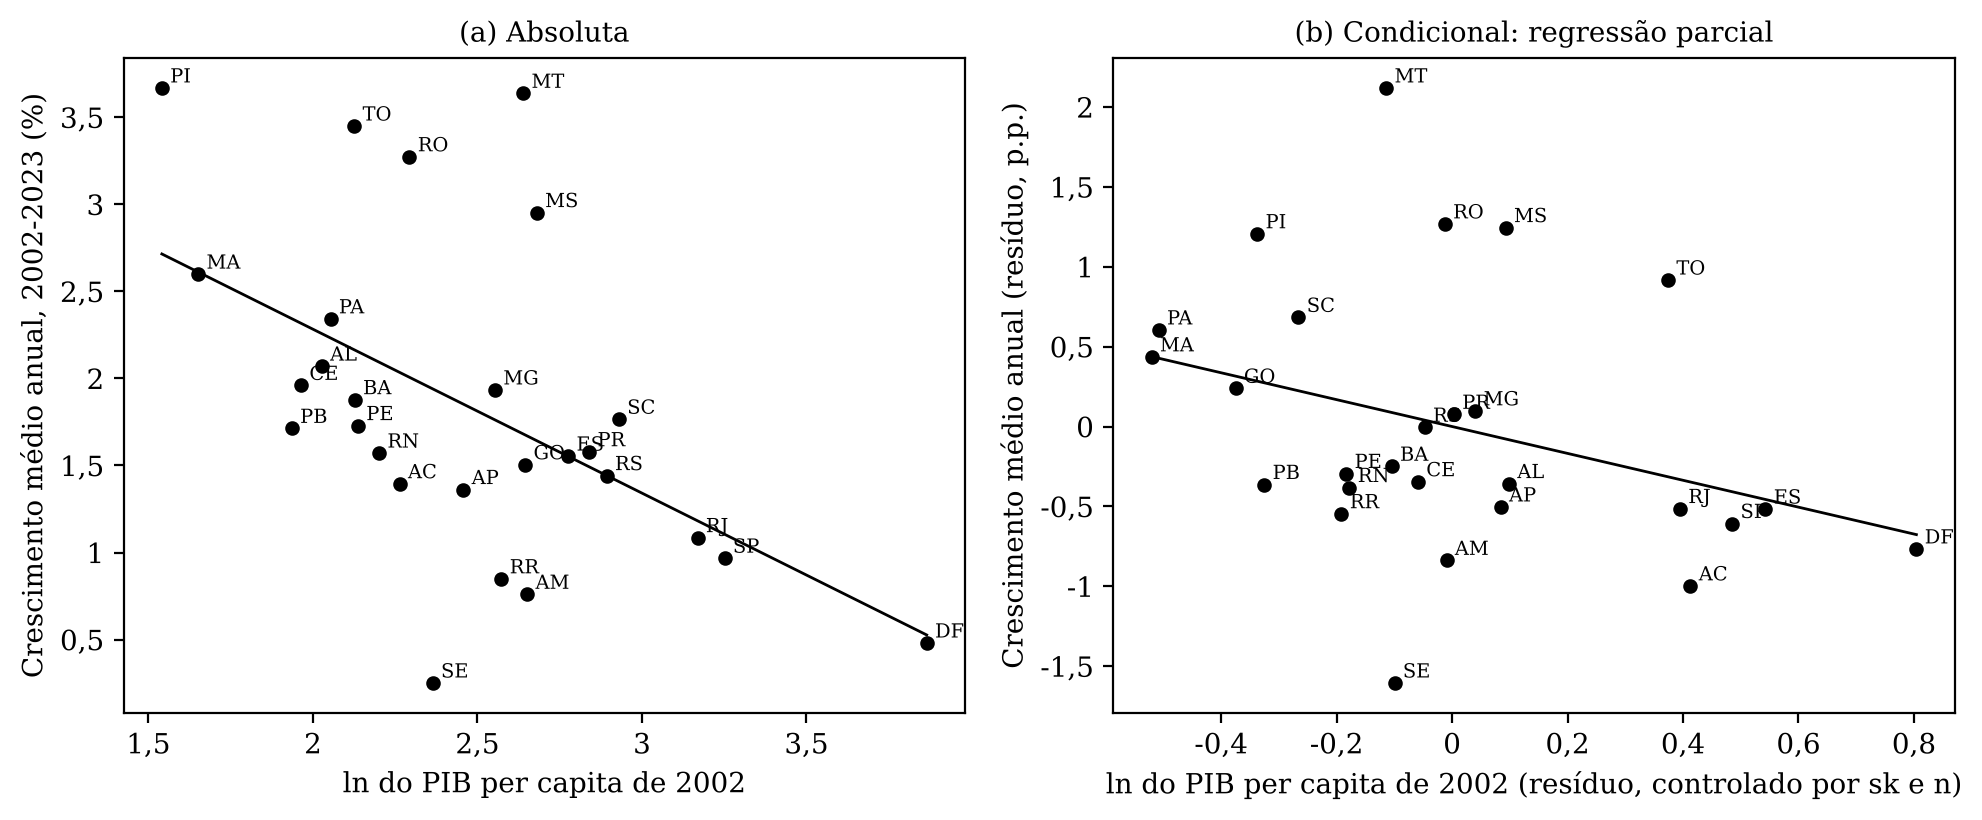

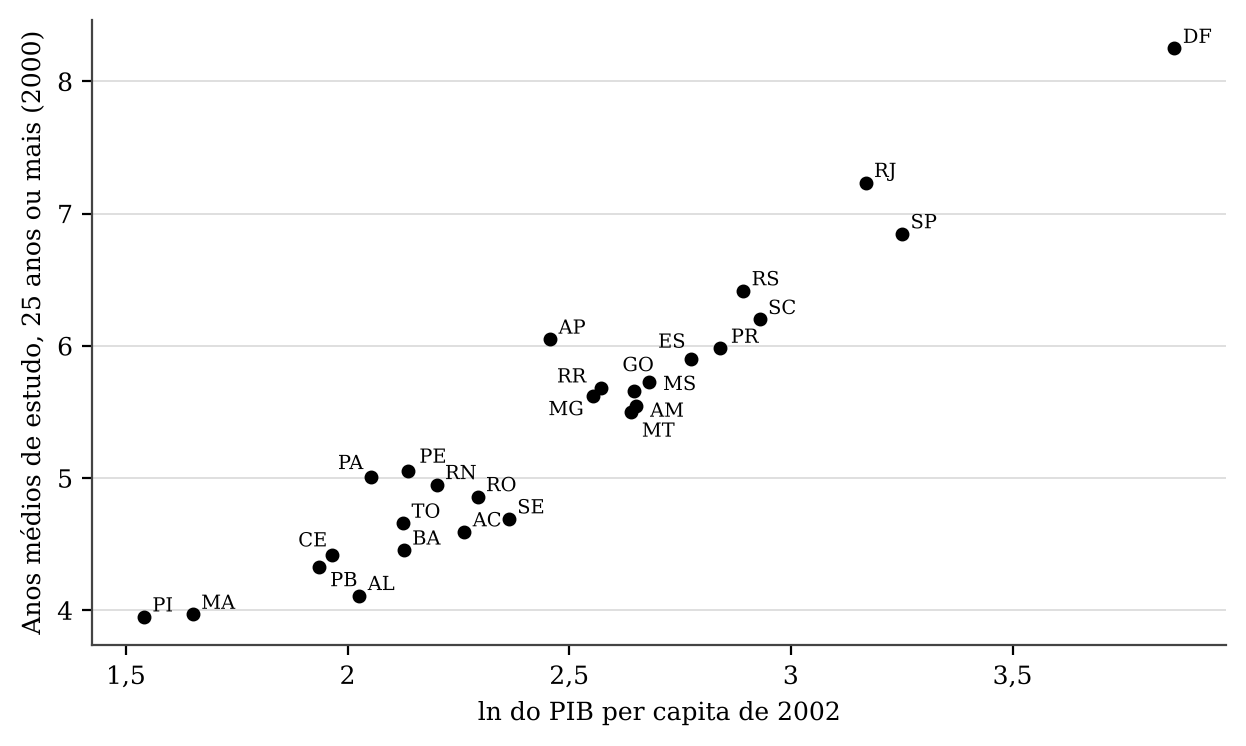

Tabelas salvas em resultados/tabelas | figuras salvas em resultados/figuras
['condicional_solow_controles.csv', 'condicional_solow_correlacoes.csv', 'condicional_solow_descritivas.csv', 'condicional_solow_escolaridade_renda_inicial.csv', 'condicional_solow_resumo.csv', 'condicional_solow_sensibilidade_gmd.csv', 'condicional_solow_vif.csv']
['condicional_solow_absoluta_x_condicional.png', 'condicional_solow_escolaridade_renda_inicial.png']


In [11]:
# ----------------------------------------------------------------------------
# 11. FIGURAS (títulos e fonte ficam no texto, no padrão do modelo da professora)
# ----------------------------------------------------------------------------
plt.rcParams.update({"font.family": "serif", "font.size": 10, "axes.formatter.use_locale": False})
from matplotlib.ticker import FuncFormatter
VIRG = FuncFormatter(lambda v, pos: f"{v:g}".replace(".", ","))

# Figura A: absoluta x condicional (regressão parcial de Frisch-Waugh-Lovell)
def residuo(y, X):
    return sm.OLS(y, sm.add_constant(X)).fit().resid

x_par = residuo(base["ln_y0"], base[CTRL])
y_par = residuo(base["cresc_medio"], base[CTRL])

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, x, y, titulo, b in [
        (axs[0], base["ln_y0"], 100 * base["cresc_medio"], "(a) Absoluta", res_abs["b"]),
        (axs[1], x_par, 100 * y_par, "(b) Condicional: regressão parcial", res_con["b"])]:
    ax.scatter(x, y, s=18, color="black")
    for uf in base.index:
        ax.annotate(uf, (x[uf], y[uf]), fontsize=7, xytext=(3, 2), textcoords="offset points")
    xs = np.linspace(x.min(), x.max(), 50)
    a = y.mean() - 100 * b * x.mean()
    ax.plot(xs, a + 100 * b * xs, color="black", lw=1)
    ax.set_title(titulo, fontsize=10)
    ax.xaxis.set_major_formatter(VIRG); ax.yaxis.set_major_formatter(VIRG)
axs[0].set_xlabel("ln do PIB per capita de 2002")
axs[0].set_ylabel("Crescimento médio anual, 2002-2023 (%)")
axs[1].set_xlabel("ln do PIB per capita de 2002 (resíduo, controlado por sk e n)")
axs[1].set_ylabel("Crescimento médio anual (resíduo, p.p.)")
plt.tight_layout()
plt.savefig(os.path.join(PASTA_FIG, PREFIXO + "absoluta_x_condicional.png"), dpi=300, bbox_inches="tight")
plt.show()

# Figura B: escolaridade (2000) x renda inicial (2002) — Figura 5 do trabalho escrito
# Padrão das figuras do texto: preto e cinza, fonte serifada de 9 pt, vírgula decimal, sem título,
# no tamanho de impressão (16 cm = 6,3 pol.)
with plt.rc_context({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#444444"}):
    fig, ax = plt.subplots(figsize=(6.3, 3.8))
    ax.scatter(base["ln_y0"], base["sh"], s=16, color="black", zorder=3)
    desloc = {"MG": (-16, -7), "RR": (-16, 2), "GO": (-4, 7), "MS": (5, -3), "AM": (5, -4), "MT": (4, -9),
              "ES": (-12, 4), "PR": (4, 2), "CE": (-12, 3), "PB": (4, -7), "PA": (-12, 3), "PE": (4, 3)}
    for uf in base.index:
        ax.annotate(uf, (base.loc[uf, "ln_y0"], base.loc[uf, "sh"]), fontsize=7,
                    xytext=desloc.get(uf, (3, 2)), textcoords="offset points")
    ax.set_xlabel("ln do PIB per capita de 2002")
    ax.set_ylabel("Anos médios de estudo, 25 anos ou mais (2000)")
    ax.xaxis.set_major_formatter(VIRG); ax.yaxis.set_major_formatter(VIRG)
    ax.grid(axis="y", color="#d9d9d9", lw=0.6, zorder=1)
    plt.tight_layout()
    plt.savefig(os.path.join(PASTA_FIG, PREFIXO + "escolaridade_renda_inicial.png"), dpi=300, bbox_inches="tight")
    plt.show()

print("Tabelas salvas em", PASTA_TAB, "| figuras salvas em", PASTA_FIG)
print(sorted(f for f in os.listdir(PASTA_TAB) if f.startswith(PREFIXO)))
print(sorted(f for f in os.listdir(PASTA_FIG) if f.startswith(PREFIXO)))